Feature	Meaning
MedInc	Median income
HouseAge	Median house age
AveRooms	Average rooms
AveBedrms	Average bedrooms
Population	District population
AveOccup	Average household occupancy
Latitude	Geographic latitude
Longitude	Geographic longitude

Target variable: MedHouseVal — median house value

In [3]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Split data into training and testing sets
from sklearn.model_selection import train_test_split

# Machine Learning algorithms
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

# Data preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Save trained model
import joblib

# Ignore unnecessary warning messages
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load California Housing dataset
housing = fetch_california_housing(as_frame=True)

# Convert dataset into a Pandas DataFrame
df = housing.frame.copy()

# Display first five rows
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
# Display dataset dimensions
print("Dataset shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns.tolist())

# Display dataset information
df.info()

Dataset shape: (20640, 9)

Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:
# Statistical summary of the dataset
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [6]:
# Count missing values in every column
print(df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [7]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


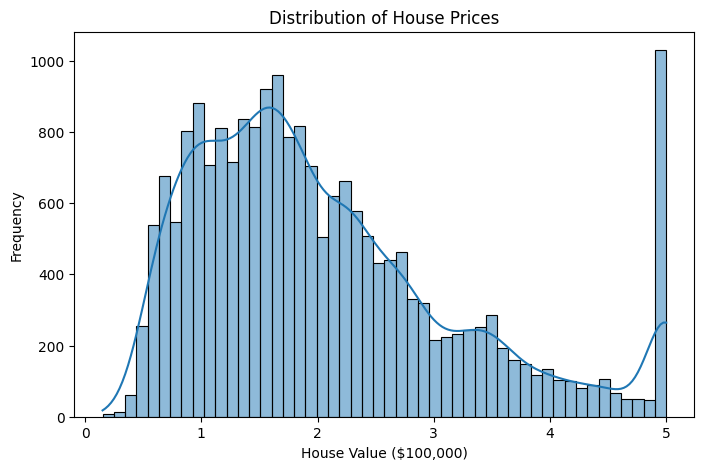

In [8]:
# Plot distribution of house prices
plt.figure(figsize=(8, 5))

sns.histplot(df["MedHouseVal"], bins=50, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Value ($100,000)")
plt.ylabel("Frequency")

plt.show()

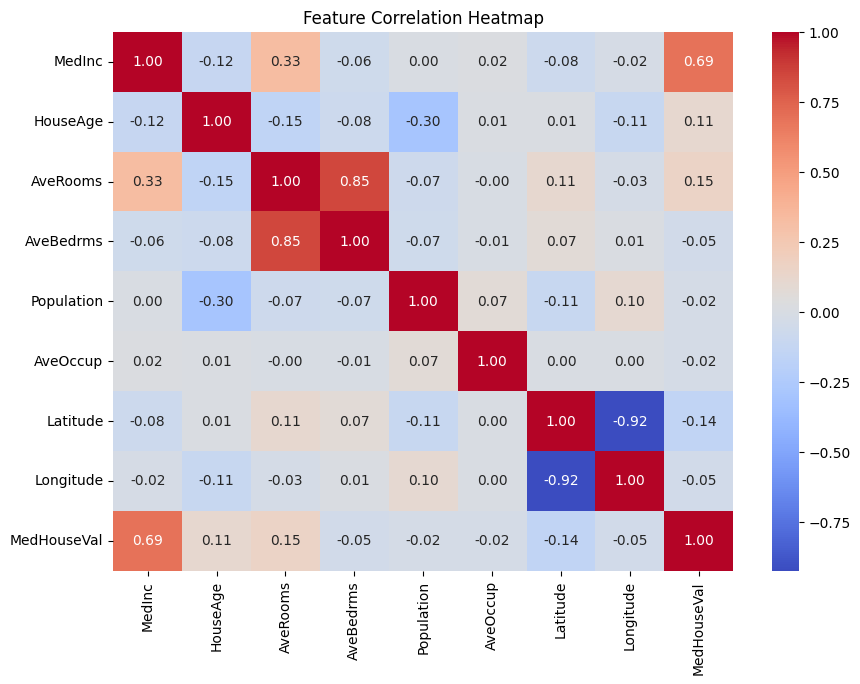

In [9]:
# Calculate correlation between numerical columns
correlation = df.corr()

# Visualize the correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [10]:
# X contains all input features
X = df.drop("MedHouseVal", axis=1)

# y contains the target variable
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [11]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display number of records
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 16512
Testing records: 4128


In [12]:
# Create a baseline model that predicts the training mean
baseline_model = DummyRegressor(strategy="mean")

# Train baseline model
baseline_model.fit(X_train, y_train)

# Predict using test data
baseline_predictions = baseline_model.predict(X_test)

In [13]:
# Create a pipeline:
# StandardScaler scales the input features.
# LinearRegression learns the relationship between features and price.
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [14]:
# Create Random Forest Regression model
random_forest_model = RandomForestRegressor(
    n_estimators=200,  # Number of decision trees
    random_state=42,   # Reproducible results
    n_jobs=-1          # Use available CPU cores
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [15]:
# Function to calculate model performance
def evaluate_model(model_name, actual, predicted):

    # Calculate Mean Absolute Error
    mae = mean_absolute_error(actual, predicted)

    # Calculate Root Mean Squared Error
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # Calculate R-squared score
    r2 = r2_score(actual, predicted)

    print("\nModel:", model_name)
    print("MAE:", round(mae, 4))
    print("RMSE:", round(rmse, 4))
    print("R2 Score:", round(r2, 4))

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }


# Generate predictions
baseline_predictions = baseline_model.predict(X_test)
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

# Evaluate all three models
results = []

results.append(
    evaluate_model("Baseline", y_test, baseline_predictions)
)

results.append(
    evaluate_model("Linear Regression", y_test, linear_predictions)
)

results.append(
    evaluate_model("Random Forest", y_test, rf_predictions)
)


Model: Baseline
MAE: 0.9061
RMSE: 1.1449
R2 Score: -0.0002

Model: Linear Regression
MAE: 0.5332
RMSE: 0.7456
R2 Score: 0.5758

Model: Random Forest
MAE: 0.3268
RMSE: 0.504
R2 Score: 0.8062


In [16]:
# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display model comparison
results_df

,Model,MAE,RMSE,R2 Score
0,Baseline,0.906069,1.144856,-0.000219
1,Linear Regression,0.533200,0.745581,0.575788
2,Random Forest,0.326812,0.503960,0.806186


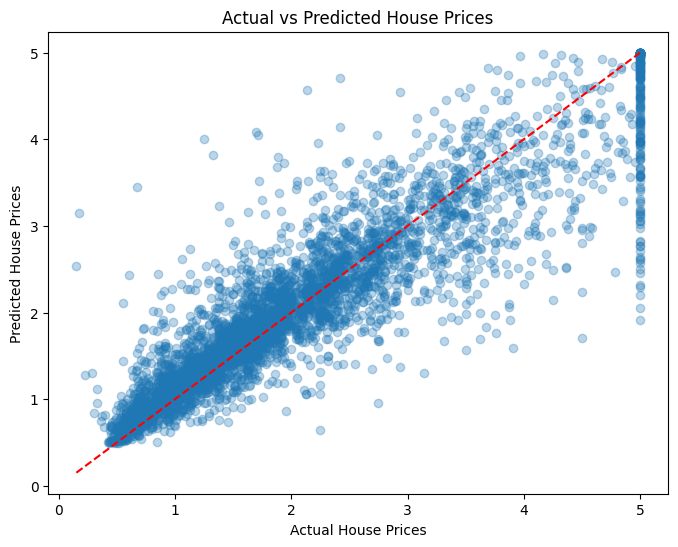

In [17]:
# Compare actual values and Random Forest predictions
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.3
)

# Reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

      Feature  Importance
0      MedInc    0.525886
5    AveOccup    0.138055
6    Latitude    0.088647
7   Longitude    0.088307
1    HouseAge    0.054355
2    AveRooms    0.044449
4  Population    0.030693
3   AveBedrms    0.029608


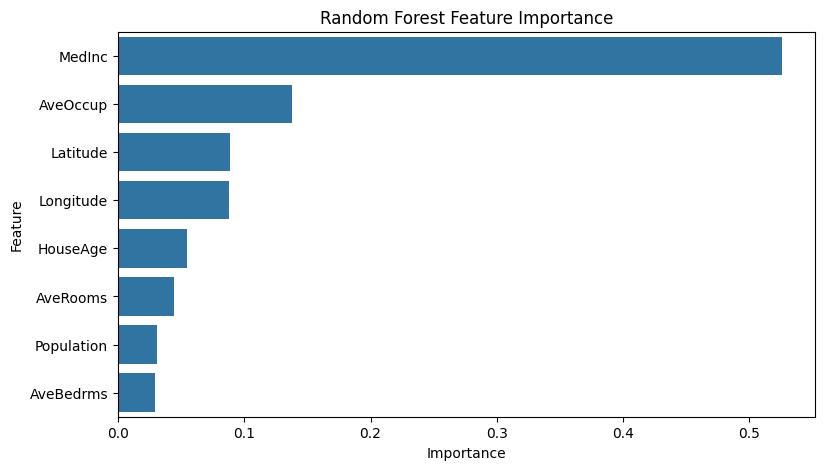

In [18]:
# Extract feature importance from Random Forest
importance = random_forest_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.show()

In [19]:
# Select one unseen example from the testing dataset
sample_house = X_test.iloc[[0]]

# Predict its house value
predicted_value = random_forest_model.predict(sample_house)[0]

# Convert the value from units of $100,000 to dollars
predicted_dollars = predicted_value * 100000

print("Predicted house value: $", round(predicted_dollars, 2))

# Display input features
print("\nHouse details:")
display(sample_house)

Predicted house value: $ 49443.0

House details:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
20046,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01


In [20]:
# Save the trained Random Forest model
joblib.dump(
    random_forest_model,
    "house_price_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [21]:
from google.colab import files

files.download("house_price_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>